# Single Image Super-Resolution with EDSR

x4 super-resolution on DIV2K using EDSR (Lim et al., 2017, "Enhanced Deep Residual Networks for Single Image Super-Resolution").

We train on random 48x48 LR patches with flip and rotation augmentation, track PSNR/SSIM on the Y channel plus LPIPS during validation, and compare the final model against bicubic interpolation. The 8x geometric self-ensemble from the paper gets its own row in the results.

Deep Learning course project at VUB (August 2026), done with Hamed Nikoo and Fahimeh Safari Moghadam. This notebook is my copy of the final version.


## 1. Imports and configuration

Every hyperparameter (paths, patch size, learning rate, model size, checkpoint dir) lives in `TrainConfig` so experiments only need changes in one place.

Everything is seeded, dataloader workers included. Without that none of these runs can be repeated, and the workers quietly hand back duplicate crops.

In [1]:
!pip install --quiet lpips "prettytable<3.10" opencv-python-headless

In [2]:
import os
import math
import glob
import zipfile
import random
import urllib.request
from dataclasses import dataclass
from typing import Tuple, Optional

import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms.functional import to_tensor
from PIL import Image
from tqdm.auto import tqdm

import lpips
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from prettytable import PrettyTable


def set_seed(seed):
    """Seed everything, including the cudnn algorithm choice."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # benchmark=True picks conv algorithms by timing them, so the choice depends on
    # what else the GPU was doing. Off means slower but repeatable.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    """Give each dataloader worker its own stream, or they hand back the same crops."""
    seed = torch.initial_seed() % 2 ** 32
    np.random.seed(seed)
    random.seed(seed)


@dataclass
class TrainConfig:
    scale: int = 4
    root_dir: str = "./Data"
    seed: int = 1234

    @property
    def data_root_train_lr(self): return os.path.join(self.root_dir, "DIV2K_train_LR_bicubic", "X4")
    @property
    def data_root_train_hr(self): return os.path.join(self.root_dir, "DIV2K_train_HR")
    @property
    def data_root_valid_lr(self): return os.path.join(self.root_dir, "DIV2K_valid_LR_bicubic", "X4")
    @property
    def data_root_valid_hr(self): return os.path.join(self.root_dir, "DIV2K_valid_HR")

    # training
    patch_size_lr: int = 48
    patches_per_image: int = 20
    batch_size: int = 32
    num_workers: int = 4
    epochs: int = 100

    # how many training images to hold back for picking checkpoints. The 100 DIV2K
    # validation images are the test set, so they cannot also choose the model.
    n_val_images: int = 10

    # optimization
    lr: float = 1e-4
    milestones: Tuple[int, ...] = (25, 40)
    gamma: float = 0.5
    amp: bool = True

    # model
    n_resblocks: int = 32
    n_feats: int = 128
    res_scale: float = 1.0

    # checkpoints
    out_dir: str = "./3runs/edsr_x4"
    keep_top_k: int = 3
    resume_path: Optional[str] = "./3runs/edsr_x4/last.pth"  # set to None to train from scratch

    device: str = "cuda" if torch.cuda.is_available() else "cpu"

/FARM/hnikoo/projects/DLProject/DeepLearningProject/v1.2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data preparation

Downloads and unzips DIV2K unless the data folder already exists, then splits it into three roles.

The download comes straight from the ETH Zurich page that publishes DIV2K rather than a Drive mirror, and only pulls the x4 set since that is the only scale used here.

The split is the important part. Previously the checkpoint was chosen on the same 100 validation images the final number was reported on, which makes that number optimistic by an amount we cannot measure. Now 10 images come out of the *training* pool for choosing checkpoints, and the official 100 are only touched at the end.

In [3]:
DIV2K_URL = "https://data.vision.ee.ethz.ch/cvl/DIV2K"
DIV2K_PARTS = [
    ("DIV2K_train_HR.zip", "DIV2K_train_HR"),
    ("DIV2K_train_LR_bicubic_X4.zip", "DIV2K_train_LR_bicubic/X4"),
    ("DIV2K_valid_HR.zip", "DIV2K_valid_HR"),
    ("DIV2K_valid_LR_bicubic_X4.zip", "DIV2K_valid_LR_bicubic/X4"),
]


def setup_data(root_dir="./Data"):
    """Fetch DIV2K x4, skipping any part that is already on disk."""
    os.makedirs(root_dir, exist_ok=True)

    for zip_name, subdir in DIV2K_PARTS:
        if os.path.isdir(os.path.join(root_dir, subdir)):
            continue

        zip_path = os.path.join(root_dir, zip_name)
        print(f"Downloading {zip_name}...")
        with urllib.request.urlopen(f"{DIV2K_URL}/{zip_name}") as resp:
            total = int(resp.headers.get("Content-Length", 0))
            with open(zip_path, "wb") as f, tqdm(total=total, unit="B", unit_scale=True) as bar:
                while chunk := resp.read(1 << 20):
                    f.write(chunk)
                    bar.update(len(chunk))

        print(f"Extracting to {root_dir}")
        with zipfile.ZipFile(zip_path) as zf:
            zf.extractall(root_dir)
        os.remove(zip_path)


def make_split(cfg):
    """Train / val / test file lists. Val comes out of the training pool, test is DIV2K valid."""
    train_pool = sorted(glob.glob(os.path.join(cfg.data_root_train_lr, "*.png")))
    test_files = sorted(glob.glob(os.path.join(cfg.data_root_valid_lr, "*.png")))
    if not train_pool or not test_files:
        raise FileNotFoundError(f"No images under {cfg.root_dir} - run setup_data() first")

    # taken from the end rather than at random, so the split survives a re-download
    return {
        "train": train_pool[:-cfg.n_val_images],
        "val": train_pool[-cfg.n_val_images:],
        "test": test_files,
    }

## 3. Evaluation metrics

PSNR and SSIM are computed on the Y (luminance) channel in the [0, 255] range, which is the convention in the super-resolution literature and makes our numbers comparable to published EDSR results. LPIPS (AlexNet backbone) adds a perceptual measure.

Two things were wrong here before:

- The Y coefficients were full-range BT.601 (0.299/0.587/0.114). The SR literature uses MATLAB `rgb2ycbcr`, which is the studio-swing version of the same standard. It is worth 1.32 dB, so it is not a rounding detail.
- The bicubic baseline used `F.interpolate`, whose kernel has a = -0.75. DIV2K's LR images came out of MATLAB `imresize`, which uses a = -0.5 and low-passes on the way down. `imresize` below is that function, so the baseline is now the actual inverse of the degradation that made the data.

In [4]:
def calc_psnr(img1, img2):
    """PSNR between two tensors in [0, 255]."""
    mse = torch.mean((img1 - img2) ** 2)
    return 20 * torch.log10(255.0 / torch.sqrt(mse))


def calc_ssim(img1, img2):
    """SSIM between two 2D (Y-channel) arrays in [0, 255], 11x11 Gaussian window."""
    C1 = (0.01 * 255) ** 2
    C2 = (0.03 * 255) ** 2

    img1 = img1.astype(np.float64)
    img2 = img2.astype(np.float64)
    kernel = cv2.getGaussianKernel(11, 1.5)
    window = np.outer(kernel, kernel.transpose())

    mu1 = cv2.filter2D(img1, -1, window)[5:-5, 5:-5]
    mu2 = cv2.filter2D(img2, -1, window)[5:-5, 5:-5]
    mu1_sq = mu1 ** 2
    mu2_sq = mu2 ** 2
    mu1_mu2 = mu1 * mu2
    sigma1_sq = cv2.filter2D(img1 ** 2, -1, window)[5:-5, 5:-5] - mu1_sq
    sigma2_sq = cv2.filter2D(img2 ** 2, -1, window)[5:-5, 5:-5] - mu2_sq
    sigma12 = cv2.filter2D(img1 * img2, -1, window)[5:-5, 5:-5] - mu1_mu2

    ssim_map = ((2 * mu1_mu2 + C1) * (2 * sigma12 + C2)) / \
               ((mu1_sq + mu2_sq + C1) * (sigma1_sq + sigma2_sq + C2))
    return ssim_map.mean()


def rgb_to_y(tensor):
    """CHW tensor in [0, 1] -> Y channel as a numpy array, MATLAB rgb2ycbcr convention."""
    img = tensor.cpu().numpy().transpose(1, 2, 0).clip(0, 1)
    return (16.0 + 65.481 * img[:, :, 0]
            + 128.553 * img[:, :, 1]
            + 24.966 * img[:, :, 2])


def shave_border(img, scale):
    # standard practice: ignore `scale` border pixels when computing metrics
    return img[..., scale:-scale, scale:-scale]


def cubic_kernel(x, a=-0.5):
    """Keys cubic kernel. MATLAB uses a = -0.5, OpenCV and PyTorch use -0.75."""
    absx = np.abs(x)
    inner = absx <= 1
    outer = (absx > 1) & (absx <= 2)
    return (((a + 2) * absx ** 3 - (a + 3) * absx ** 2 + 1) * inner
            + (a * absx ** 3 - 5 * a * absx ** 2 + 8 * a * absx - 4 * a) * outer)


def resize_matrix(in_len, out_len, a=-0.5):
    """Weights for a 1-D MATLAB-style resize along one axis."""
    s = out_len / in_len
    width = 4.0 if s >= 1 else 4.0 / s          # widen the kernel when shrinking (anti-aliasing)

    u = np.arange(1, out_len + 1) / s + 0.5 * (1 - 1 / s)   # half-pixel centres
    left = np.floor(u - width / 2)
    taps = int(math.ceil(width)) + 2
    idx = left[:, None] + np.arange(taps)[None, :]

    w = cubic_kernel(u[:, None] - idx, a) if s >= 1 else s * cubic_kernel(s * (u[:, None] - idx), a)
    w /= w.sum(axis=1, keepdims=True)

    idx = np.clip(idx - 1, 0, in_len - 1).astype(int)       # MATLAB counts from 1
    mat = np.zeros((out_len, in_len))
    rows = np.arange(out_len)[:, None].repeat(taps, axis=1)
    np.add.at(mat, (rows.ravel(), idx.ravel()), w.ravel())
    return mat


def imresize(img, scale):
    """MATLAB-compatible bicubic resize of an HxWxC float image. Separable, so rows then columns."""
    h, w = img.shape[:2]
    mh = resize_matrix(h, int(round(h * scale)))
    mw = resize_matrix(w, int(round(w * scale)))
    out = np.einsum("ij,jkc->ikc", mh, img)
    return np.einsum("ij,kjc->kic", mw, out)


def bicubic_upsample(lr, scale):
    """Upsample an NCHW batch in [0, 1] with the kernel that built the dataset."""
    out = []
    for img in lr:
        arr = img.permute(1, 2, 0).cpu().numpy().astype(np.float64)
        out.append(torch.from_numpy(imresize(arr, scale)).permute(2, 0, 1).float())
    return torch.stack(out).to(lr.device).clamp(0, 1)

## 4. Dataset

For training we sample several random 48x48 LR patches per image (with the matching x4 HR crop) and apply random flips and a transpose. For validation and test we use the full images, cropped so their size is divisible by the scale factor.

Two flips give 4 of the 8 dihedral symmetries. The self-ensemble at test time averages over all 8, so it was leaning on an invariance the training had only half taught. The transpose completes it.

The `cache_in_ram` option is gone. It needed about 7 GB, the original carried a note saying to remove it before submission, and it does not survive `num_workers > 0` because each worker forks its own copy.

In [5]:
class DIV2KDataset(Dataset):
    def __init__(self, lr_files, hr_dir, scale, patch_size=None, patches_per_img=1, train=True):
        self.lr_files = lr_files
        if not self.lr_files:
            raise FileNotFoundError("empty file list - run setup_data() and make_split() first")
        self.hr_dir = hr_dir
        self.scale = scale
        self.patch_size = patch_size
        self.train = train

        # repeat indices so one epoch sees several patches per image
        self.idx_map = []
        for i in range(len(self.lr_files)):
            self.idx_map.extend([i] * patches_per_img)

        print(f"{len(self.lr_files)} images, {len(self.idx_map)} samples per epoch")

    def __len__(self):
        return len(self.idx_map)

    def __getitem__(self, idx):
        lr_path = self.lr_files[self.idx_map[idx]]
        name = os.path.basename(lr_path)
        hr_name = name.replace("x4", "").replace("X4", "")
        hr_path = os.path.join(self.hr_dir, hr_name)

        lr = Image.open(lr_path).convert("RGB")
        hr = Image.open(hr_path).convert("RGB")

        if self.train:
            lr_w, lr_h = lr.size

            # random crop, same region in LR and HR
            ix = random.randint(0, lr_w - self.patch_size)
            iy = random.randint(0, lr_h - self.patch_size)
            lr = lr.crop((ix, iy, ix + self.patch_size, iy + self.patch_size))
            hr = hr.crop((ix * self.scale, iy * self.scale,
                          (ix + self.patch_size) * self.scale, (iy + self.patch_size) * self.scale))

            # two flips plus a transpose generate all 8 symmetries of a square
            if random.random() < 0.5:
                lr = lr.transpose(Image.FLIP_LEFT_RIGHT)
                hr = hr.transpose(Image.FLIP_LEFT_RIGHT)
            if random.random() < 0.5:
                lr = lr.transpose(Image.FLIP_TOP_BOTTOM)
                hr = hr.transpose(Image.FLIP_TOP_BOTTOM)
            if random.random() < 0.5:
                lr = lr.transpose(Image.TRANSPOSE)
                hr = hr.transpose(Image.TRANSPOSE)
        else:
            # crop so dimensions are divisible by the scale factor
            w, h = lr.size
            w -= w % self.scale
            h -= h % self.scale
            lr = lr.crop((0, 0, w, h))
            hr = hr.crop((0, 0, w * self.scale, h * self.scale))

        return to_tensor(lr), to_tensor(hr), name


def make_loaders(cfg, split):
    g = torch.Generator()
    g.manual_seed(cfg.seed)

    train_ds = DIV2KDataset(split["train"], cfg.data_root_train_hr, cfg.scale,
                            cfg.patch_size_lr, cfg.patches_per_image, train=True)
    val_ds = DIV2KDataset(split["val"], cfg.data_root_train_hr, cfg.scale, train=False)
    test_ds = DIV2KDataset(split["test"], cfg.data_root_valid_hr, cfg.scale, train=False)

    # worker_init_fn and generator keep the patch sequence reproducible
    train_loader = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True,
                              num_workers=cfg.num_workers, pin_memory=True,
                              worker_init_fn=seed_worker, generator=g)
    val_loader = DataLoader(val_ds, batch_size=1, shuffle=False, num_workers=min(2, cfg.num_workers))
    test_loader = DataLoader(test_ds, batch_size=1, shuffle=False, num_workers=min(2, cfg.num_workers))
    return train_loader, val_loader, test_loader

## 5. EDSR architecture

The model follows the original paper: a conv head, a long chain of residual blocks, a global skip connection, and PixelShuffle upsampling at the end.

Design choices, and why:
- **MeanShift** subtracts the DIV2K channel means from the input (and adds them back at the output). The network then works on roughly zero-centered data, which trains more stably. It is a fixed 1x1 conv inside the model, so at inference we can feed normal [0,1] images without any external preprocessing.
- **No batch normalization** in the residual blocks: this is the key EDSR change vs. SRResNet. BN normalizes feature statistics, which throws away per-image contrast/brightness information that super-resolution needs to reconstruct pixels. Removing BN also saves memory, so the network can be deeper.
- **Upsampling only at the end** (PixelShuffle): all 32 residual blocks run at low resolution (16x fewer pixels for x4), which is much cheaper. PixelShuffle rearranges channels (4*C, H, W) -> (C, 2H, 2W) with learned filters and avoids the checkerboard artifacts of transposed convolutions.
- **Global skip connection** (`x + res`): the body only has to learn the missing high-frequency details, the low-frequency content is carried through directly.

In [6]:
class MeanShift(nn.Conv2d):
    def __init__(self, rgb_range, rgb_mean, rgb_std, sign=-1):
        super().__init__(3, 3, kernel_size=1)
        std = torch.Tensor(rgb_std)
        self.weight.data = torch.eye(3).view(3, 3, 1, 1)
        self.weight.data.div_(std.view(3, 1, 1, 1))
        self.bias.data = sign * rgb_range * torch.Tensor(rgb_mean)
        self.bias.data.div_(std)
        for p in self.parameters():
            p.requires_grad = False


class ResBlock(nn.Module):
    def __init__(self, n_feats, res_scale=1.0):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(n_feats, n_feats, 3, 1, 1),
            nn.ReLU(inplace=True),
            nn.Conv2d(n_feats, n_feats, 3, 1, 1),
        )
        self.res_scale = res_scale

    def forward(self, x):
        return x + self.body(x) * self.res_scale


class Upsampler(nn.Sequential):
    def __init__(self, scale, n_feats):
        if scale & (scale - 1) != 0:
            raise NotImplementedError("only power-of-2 scales supported")
        m = []
        for _ in range(int(math.log2(scale))):
            m.append(nn.Conv2d(n_feats, 4 * n_feats, 3, 1, 1))
            m.append(nn.PixelShuffle(2))
        super().__init__(*m)


class EDSR(nn.Module):
    def __init__(self, scale, n_resblocks, n_feats, res_scale=1.0):
        super().__init__()
        rgb_mean = (0.4488, 0.4371, 0.4040)  # DIV2K channel means
        rgb_std = (1.0, 1.0, 1.0)

        self.sub_mean = MeanShift(1.0, rgb_mean, rgb_std, sign=-1)
        self.head = nn.Conv2d(3, n_feats, 3, 1, 1)
        self.body = nn.Sequential(*[ResBlock(n_feats, res_scale) for _ in range(n_resblocks)])
        self.tail = nn.Conv2d(n_feats, n_feats, 3, 1, 1)
        self.upsampler = Upsampler(scale, n_feats)
        self.output_conv = nn.Conv2d(n_feats, 3, 3, 1, 1)
        self.add_mean = MeanShift(1.0, rgb_mean, rgb_std, sign=1)

    def forward(self, x):
        x = self.sub_mean(x)
        x = self.head(x)
        res = self.tail(self.body(x))
        x = x + res
        x = self.upsampler(x)
        x = self.output_conv(x)
        return self.add_mean(x)


def make_model(cfg):
    return EDSR(cfg.scale, cfg.n_resblocks, cfg.n_feats, cfg.res_scale)

## 6. Training utilities

Checkpoint save/load (keeps the top-k best-PSNR weights plus `last.pth` for resuming), one training epoch with L1 loss and optional mixed precision, and one evaluation loop. `geometric_ensemble` averages predictions over the 8 flip/rotation variants of the input, the self-ensemble trick from the EDSR paper.

There is a single `evaluate` now. Previously per-epoch validation shaved a 4-pixel border and the final evaluation did not, so the training curves and the results table were measuring different quantities and both appeared in the same report. Everything goes through one function.

The checkpoint also carries the RNG state. Without it a resumed run draws a different patch sequence than an uninterrupted one, so "resume" quietly becomes a different experiment.

In [7]:
def rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }


def save_checkpoint(state, is_best, out_dir, epoch, keep_top_k=3):
    os.makedirs(out_dir, exist_ok=True)
    torch.save(state, os.path.join(out_dir, "last.pth"))

    if is_best:
        torch.save(state, os.path.join(out_dir, f"best_psnr_epoch_{epoch:04d}.pth"))
        all_bests = sorted(glob.glob(os.path.join(out_dir, "best_psnr_*.pth")), key=os.path.getmtime)
        for old in all_bests[:-keep_top_k]:
            try:
                os.remove(old)
            except OSError:
                pass


def load_checkpoint(path, model, optimizer=None, scheduler=None, restore_rng=True):
    print(f"Resuming from {path}")
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    model.load_state_dict(ckpt["model"])
    if optimizer and "optimizer" in ckpt:
        optimizer.load_state_dict(ckpt["optimizer"])
    if scheduler and "scheduler" in ckpt:
        scheduler.load_state_dict(ckpt["scheduler"])

    if restore_rng and ckpt.get("rng"):
        r = ckpt["rng"]
        random.setstate(r["python"])
        np.random.set_state(r["numpy"])
        torch.set_rng_state(r["torch"])
        if r["cuda"] and torch.cuda.is_available():
            torch.cuda.set_rng_state_all(r["cuda"])

    history = ckpt.get("history", {"loss": [], "psnr": [], "ssim": [], "lpips": []})
    return ckpt.get("epoch", 0) + 1, ckpt.get("best_psnr", -1.0), history


def geometric_ensemble(model, x):
    def forward_aug(img, k):
        if k >= 4:
            img = img.flip([3])
        return torch.rot90(img, k % 4, [2, 3])

    def inverse_aug(img, k):
        # inverse of "flip then rotate" is "rotate back then flip", in that order
        img = torch.rot90(img, -(k % 4), [2, 3])
        if k >= 4:
            img = img.flip([3])
        return img

    sr_total = 0
    for k in range(8):
        sr_total += inverse_aug(model(forward_aug(x, k)), k)
    return sr_total / 8.0


def train_one_epoch(model, loader, optimizer, criterion, device, scaler=None):
    model.train()
    total_loss = 0.0

    for lr, hr, _ in tqdm(loader, desc="Training", leave=False):
        lr, hr = lr.to(device), hr.to(device)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.amp.autocast("cuda"):
                loss = criterion(model(lr), hr)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss = criterion(model(lr), hr)
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
    return total_loss / len(loader)


@torch.no_grad()
def evaluate(predict, loader, device, lpips_fn=None, scale=4, desc="Evaluating"):
    """The one evaluation path. `predict` is anything callable: a model, or a lambda for bicubic."""
    psnr_list, ssim_list, lpips_list = [], [], []

    for lr, hr, _ in tqdm(loader, desc=desc, leave=False):
        lr, hr = lr.to(device), hr.to(device)
        sr = predict(lr).clamp(0, 1)

        # everything scored on the same shaved crop, so all three numbers describe the same pixels
        sr_s = shave_border(sr, scale)
        hr_s = shave_border(hr, scale)
        sr_y = rgb_to_y(sr_s[0])
        hr_y = rgb_to_y(hr_s[0])

        psnr_list.append(calc_psnr(torch.tensor(sr_y), torch.tensor(hr_y)).item())
        ssim_list.append(calc_ssim(sr_y, hr_y))
        if lpips_fn:
            lpips_list.append(lpips_fn(sr_s * 2 - 1, hr_s * 2 - 1).item())

    return {
        "PSNR": np.mean(psnr_list),
        "SSIM": np.mean(ssim_list),
        "LPIPS": np.mean(lpips_list) if lpips_list else float("nan"),
    }

## 7. Training

Builds the model, loss and optimizer, then trains for `cfg.epochs` epochs, validating after each one on the 10 held-out training images. Resumes from `cfg.resume_path` if that checkpoint exists.

- **L1 loss** instead of L2: L2 matches PSNR mathematically, but in practice L1 converges better and gives sharper images (this is what the EDSR paper uses).
- **Adam, lr 1e-4, halved at the milestones** (MultiStepLR): the standard EDSR training recipe.
- **Mixed precision (AMP)** on GPU: float16 compute for speed and memory, with a gradient scaler to avoid underflow.

In [8]:
def main():
    cfg = TrainConfig()
    set_seed(cfg.seed)
    print(f"Device: {cfg.device}")

    setup_data(cfg.root_dir)
    split = make_split(cfg)
    for role, files in split.items():
        print(f"{role:>5}: {len(files):>4} images")

    lpips_fn = lpips.LPIPS(net="alex").to(cfg.device)
    train_loader, val_loader, test_loader = make_loaders(cfg, split)

    model = make_model(cfg).to(cfg.device)
    criterion = nn.L1Loss()
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=cfg.milestones, gamma=cfg.gamma)
    # torch.amp.GradScaler("cuda") only exists from torch 2.3 on, and the farm runs 2.1.2.
    # The torch.cuda.amp spelling works on both, it just warns on the newer ones.
    scaler = torch.cuda.amp.GradScaler() if cfg.amp and cfg.device == "cuda" else None

    history = {"loss": [], "psnr": [], "ssim": [], "lpips": []}
    start_epoch, best_psnr = 1, -1.0

    if cfg.resume_path and os.path.exists(cfg.resume_path):
        start_epoch, best_psnr, history = load_checkpoint(cfg.resume_path, model, optimizer, scheduler)

    print(f"Training from epoch {start_epoch}")
    for epoch in range(start_epoch, cfg.epochs + 1):
        loss = train_one_epoch(model, train_loader, optimizer, criterion, cfg.device, scaler)
        scheduler.step()

        model.eval()
        metrics = evaluate(model, val_loader, cfg.device, lpips_fn, cfg.scale, desc="Validating")
        history["loss"].append(loss)
        history["psnr"].append(metrics["PSNR"])
        history["ssim"].append(metrics["SSIM"])
        history["lpips"].append(metrics["LPIPS"])

        is_best = metrics["PSNR"] > best_psnr
        best_psnr = max(best_psnr, metrics["PSNR"])

        save_checkpoint({
            "epoch": epoch,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "best_psnr": best_psnr,
            "history": history,
            "rng": rng_state(),
        }, is_best, cfg.out_dir, epoch, cfg.keep_top_k)

        print(f"[{epoch:03d}/{cfg.epochs}] loss {loss:.4f} | PSNR {metrics['PSNR']:.2f} | best {best_psnr:.2f}")

    return model, test_loader, cfg, lpips_fn


model, test_loader, cfg, lpips_fn = main()

Device: cuda
train:  790 images
  val:   10 images
 test:  100 images
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/apps/zen4/software/torchvision/0.16.0-foss-2023a-CUDA-12.1.1/lib/python3.11/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/apps/zen4/software/torchvision/0.16.0-foss-2023a-CUDA-12.1.1/lib/python3.11/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /FARM/hnikoo/projects/DLProject/DeepLearningProject/v1.2/.venv/lib/python3.11/site-packages/lpips/weights/v0.1/alex.pth
790 images, 15800 samples per epoch
10 images, 10 samples per epoch
100 images, 100 samples per epoch
Training from epoch 1



Training:  37%|███▋      | 184/494 [01:34<02:17,  2.26it/s]


Training:  87%|████████▋ | 432/494 [03:40<00:25,  2.40it/s]


...

[099/100] loss 0.0246 | PSNR 31.24 | best 31.27



Training:  42%|████▏     | 209/494 [01:49<03:09,  1.50it/s]


Training:  79%|███████▉  | 390/494 [03:21<00:57,  1.79it/s]


Training: 100%|█████████▉| 493/494 [04:14<00:00,  1.98it/s]
                                                           
Validating: 100%|██████████| 10/10 [00:03<00:00,  3.05it/s]


[100/100] loss 0.0245 | PSNR 31.26 | best 31.27


## 8. Final evaluation

The trained model against bicubic interpolation on the 100 held-out DIV2K validation images: Y-channel PSNR and SSIM plus LPIPS (lower is better).

Three changes from before. The score comes from the best checkpoint rather than whichever epoch happened to be last. Everything goes through the same `evaluate` used during training, so these numbers and the curves are comparable. And the self-ensemble finally has a row: it was implemented and described in the report, but `use_ensemble` defaulted to False and nothing ever passed True, so it never actually ran.

In [9]:
# score from the best checkpoint, not whatever the last epoch produced
best_files = sorted(glob.glob(os.path.join(cfg.out_dir, "best_psnr_*.pth")), key=os.path.getmtime)
if best_files:
    load_checkpoint(best_files[-1], model, restore_rng=False)
model.eval()

rows = {
    "Bicubic": evaluate(lambda x: bicubic_upsample(x, cfg.scale), test_loader, cfg.device,
                        lpips_fn, cfg.scale, desc="Bicubic"),
    "EDSR": evaluate(model, test_loader, cfg.device, lpips_fn, cfg.scale, desc="EDSR"),
    "EDSR + 8x self-ensemble": evaluate(lambda x: geometric_ensemble(model, x), test_loader,
                                        cfg.device, lpips_fn, cfg.scale, desc="EDSR+SE"),
}

table = PrettyTable(["", "Y-PSNR", "Y-SSIM", "LPIPS"])
table.align[""] = "l"
for name, s in rows.items():
    table.add_row([name, f"{s['PSNR']:.2f}", f"{s['SSIM']:.4f}", f"{s['LPIPS']:.4f}"])

print(f"DIV2K x{cfg.scale}, {len(test_loader.dataset)} held-out test images.\n")
print(table)

Resuming from ./3runs/edsr_x4/best_psnr_epoch_0097.pth



Bicubic: 100%|██████████| 100/100 [02:09<00:00,  1.18s/it]
                                                          
EDSR:  41%|████      | 41/100 [00:13<00:19,  3.09it/s]


EDSR: 100%|██████████| 100/100 [00:33<00:00,  3.26it/s]
                                                       
EDSR+SE:  83%|████████▎ | 83/100 [01:15<00:15,  1.10it/s]


EDSR+SE: 100%|██████████| 100/100 [01:30<00:00,  1.19it/s]
                                                          

DIV2K x4, 100 held-out test images.

+-------------------------+--------+--------+--------+
|                         | Y-PSNR | Y-SSIM | LPIPS  |
+-------------------------+--------+--------+--------+
| Bicubic                 | 28.09  | 0.7744 | 0.4139 |
| EDSR                    | 30.41  | 0.8371 | 0.2804 |
| EDSR + 8x self-ensemble | 30.48  | 0.8384 | 0.2828 |
+-------------------------+--------+--------+--------+


## 9. Qualitative results

Numbers only tell part of the story, so we also look at the images: pick a validation image, zoom into a 200x200 center crop, and compare bicubic against EDSR side by side. EDSR should recover noticeably sharper edges and textures.

The per-image PSNR printed under each crop is now Y-channel, matching the table. Previously the figures printed RGB PSNR next to a table of Y-channel PSNR, so the two sets of dB numbers in the report could not be compared with each other. The image index is fixed rather than random, because a figure nobody can regenerate is not evidence.

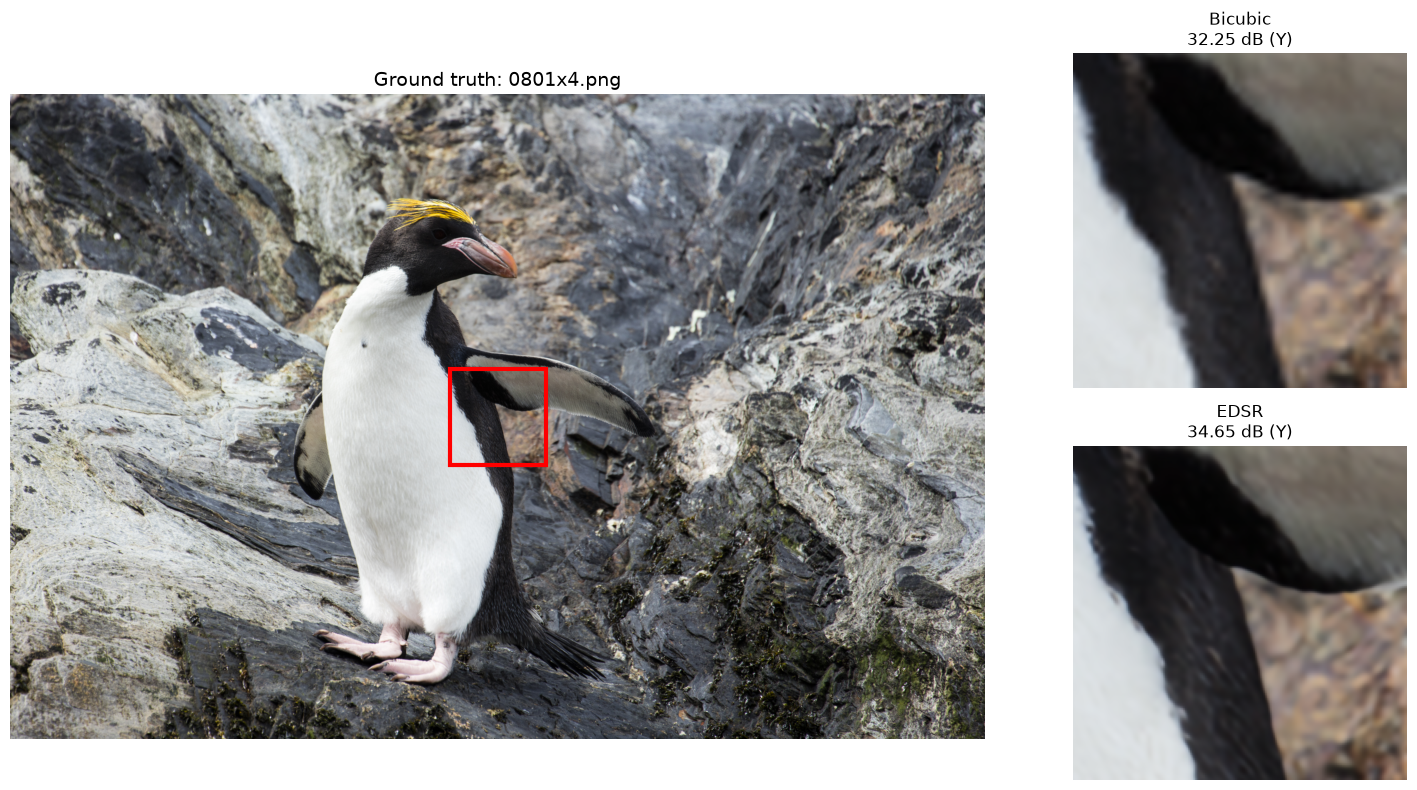

In [10]:
def tensor_to_image(tensor):
    return tensor.detach().cpu().numpy().transpose(1, 2, 0).clip(0, 1)


@torch.no_grad()
def show_full_and_zoom(model, loader, device, scale=4, index=0):
    model.eval()

    index = min(index, len(loader.dataset) - 1)
    lr, hr, name = loader.dataset[index]
    lr = lr.unsqueeze(0).to(device)
    hr = hr.unsqueeze(0).to(device)

    bicubic = bicubic_upsample(lr, scale)
    sr = model(lr).clamp(0, 1)

    # zoom into a center crop so fine details are visible
    zoom = 200
    _, _, h, w = hr.shape
    x0, y0 = (w - zoom) // 2, (h - zoom) // 2

    hr_crop = hr[:, :, y0:y0 + zoom, x0:x0 + zoom]
    bic_crop = bicubic[:, :, y0:y0 + zoom, x0:x0 + zoom]
    sr_crop = sr[:, :, y0:y0 + zoom, x0:x0 + zoom]

    # Y channel, same as the results table
    hr_y = rgb_to_y(hr_crop[0])
    psnr_bic = calc_psnr(torch.tensor(rgb_to_y(bic_crop[0])), torch.tensor(hr_y)).item()
    psnr_sr = calc_psnr(torch.tensor(rgb_to_y(sr_crop[0])), torch.tensor(hr_y)).item()

    plt.figure(figsize=(15, 8))
    ax_main = plt.subplot2grid((2, 3), (0, 0), colspan=2, rowspan=2)
    ax_main.imshow(tensor_to_image(hr[0]))
    ax_main.set_title(f"Ground truth: {name}", fontsize=14)
    ax_main.axis("off")
    ax_main.add_patch(patches.Rectangle((x0, y0), zoom, zoom, linewidth=3,
                                        edgecolor="red", facecolor="none"))

    for pos, img, title, psnr in [((0, 2), bic_crop, "Bicubic", psnr_bic),
                                  ((1, 2), sr_crop, "EDSR", psnr_sr)]:
        ax = plt.subplot2grid((2, 3), pos)
        ax.imshow(tensor_to_image(img[0]))
        ax.set_title(f"{title}\n{psnr:.2f} dB (Y)", fontsize=12)
        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_full_and_zoom(model, test_loader, cfg.device, cfg.scale, index=0)

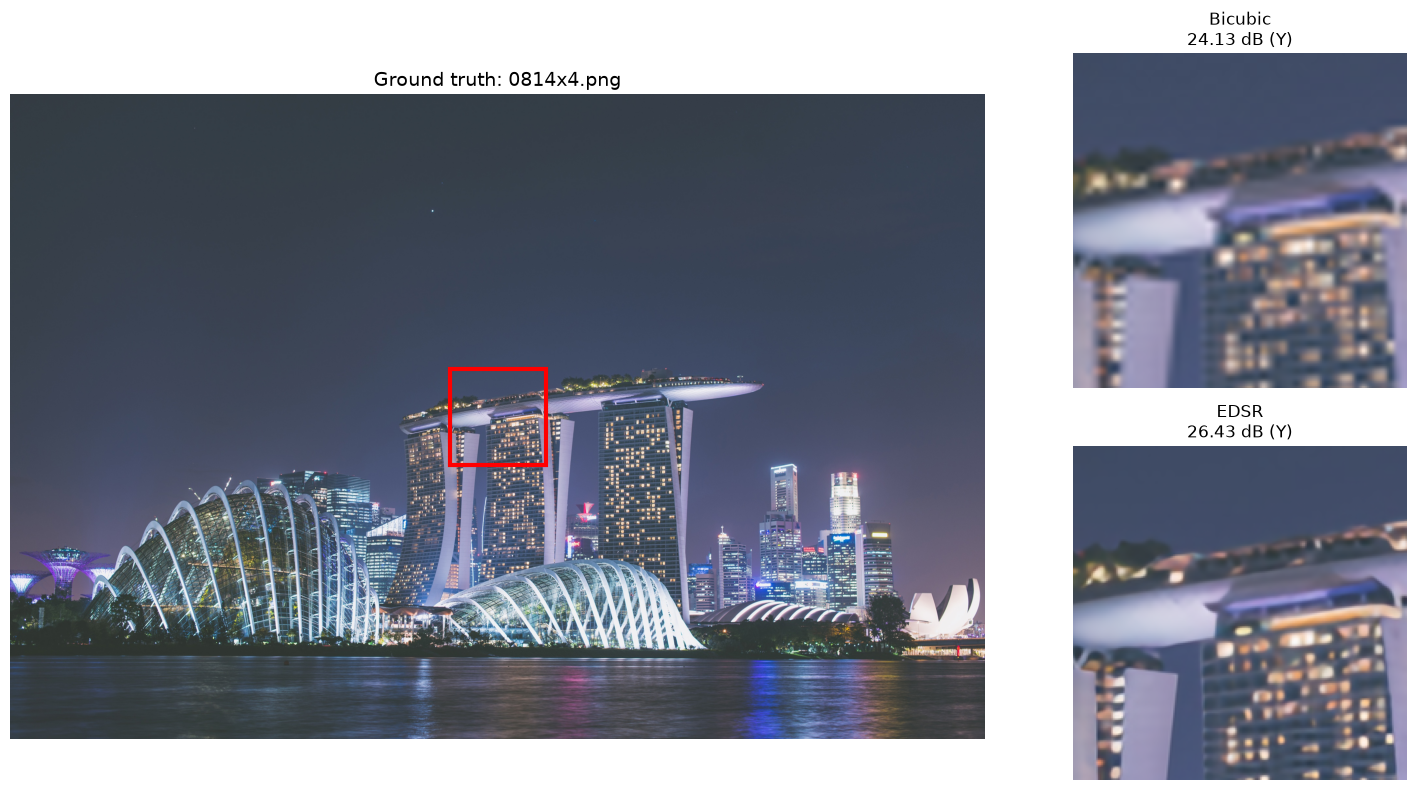

In [11]:
# another sample
show_full_and_zoom(model, test_loader, cfg.device, cfg.scale, index=13)

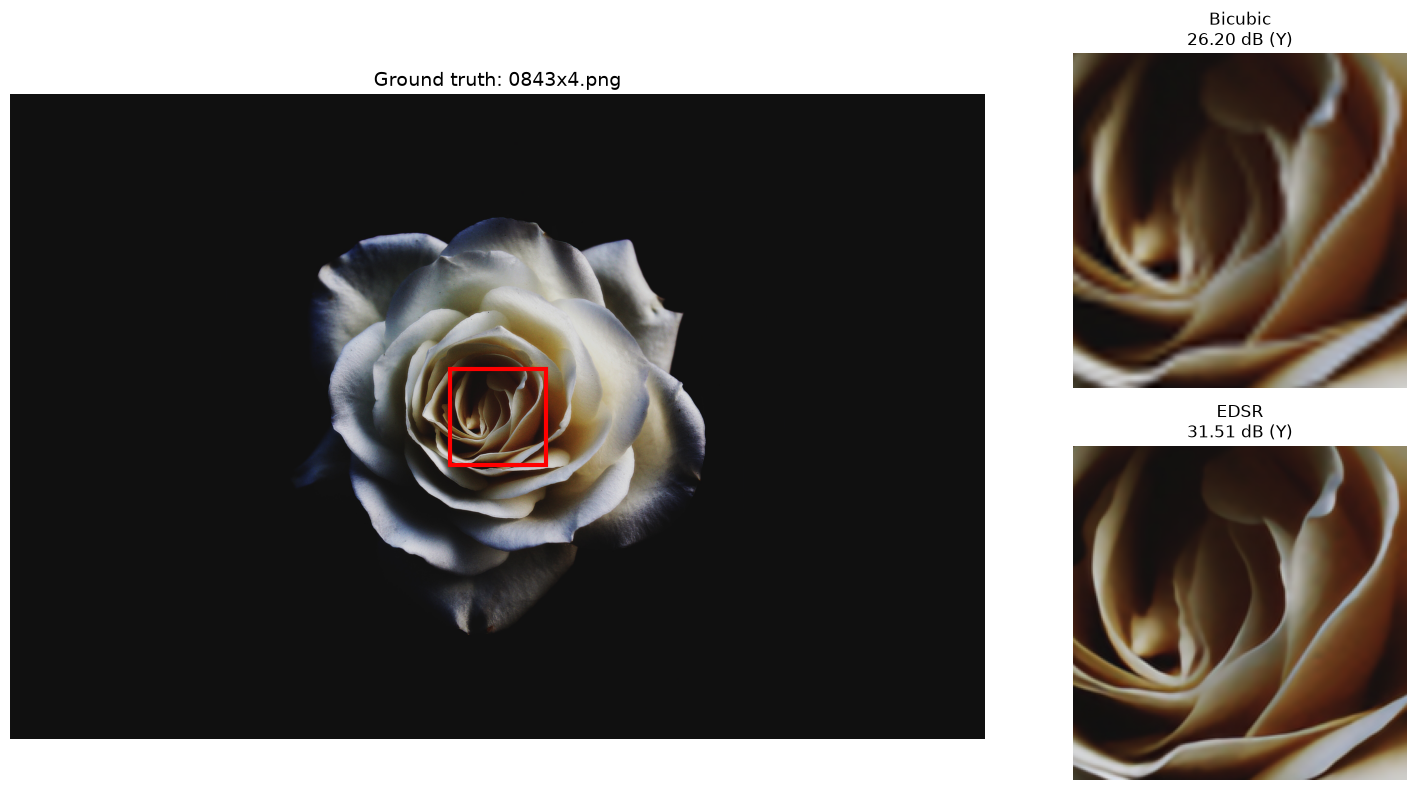

In [12]:
# and one more
show_full_and_zoom(model, test_loader, cfg.device, cfg.scale, index=42)

## 10. Training curves

Loss, PSNR and LPIPS per epoch, read back out of the checkpoint so the plots survive a kernel restart.

In [13]:
checkpoint_path = cfg.resume_path or os.path.join(cfg.out_dir, "last.pth")
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
history = checkpoint["history"]
epochs = range(1, len(history["loss"]) + 1)

print(f"Loaded {checkpoint_path}")
print(f"Best validation PSNR:  {checkpoint['best_psnr']:.2f} dB")
print(f"Best validation LPIPS: {min(history['lpips']):.4f}")

Loaded ./3runs/edsr_x4/last.pth
Best validation PSNR:  31.27 dB
Best validation LPIPS: 0.2393


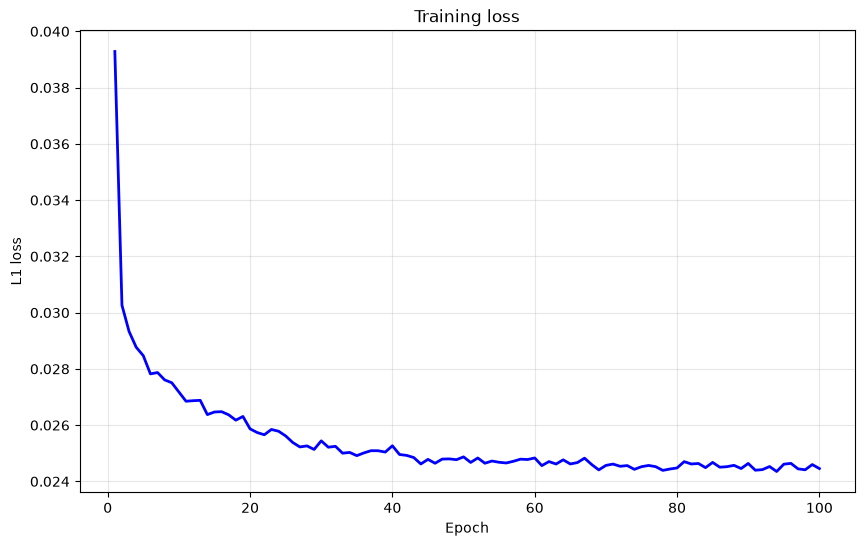

In [14]:
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["loss"], "b-", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("L1 loss")
plt.title("Training loss")
plt.grid(alpha=0.3)
plt.show()

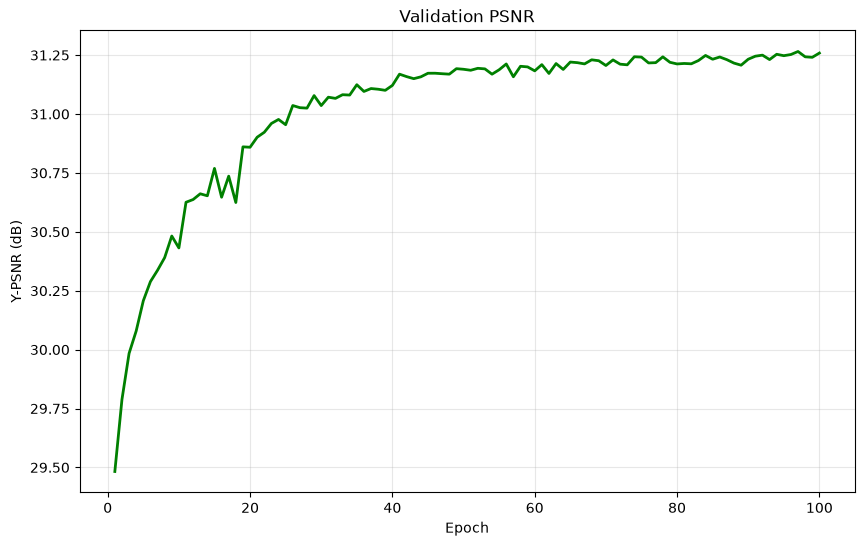

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["psnr"], "g-", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Y-PSNR (dB)")
plt.title("Validation PSNR")
plt.grid(alpha=0.3)
plt.show()

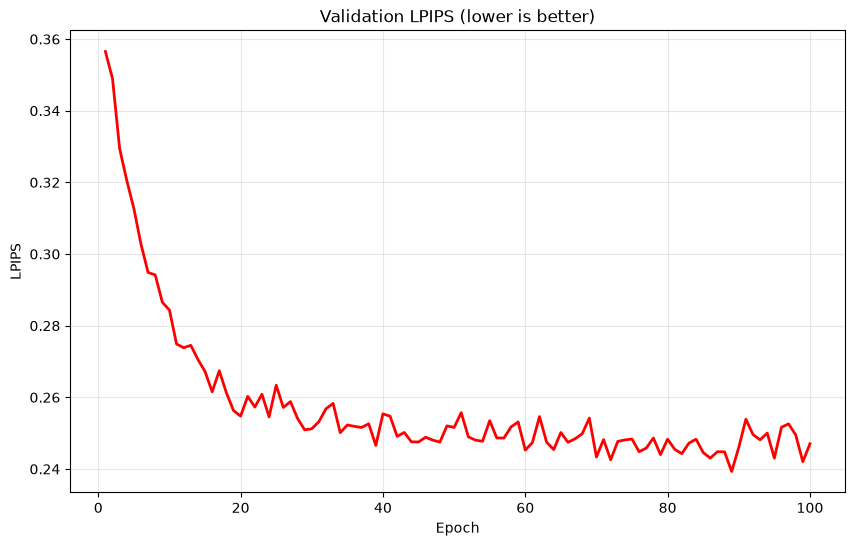

In [16]:
plt.figure(figsize=(10, 6))
plt.plot(epochs, history["lpips"], "r-", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("LPIPS")
plt.title("Validation LPIPS (lower is better)")
plt.grid(alpha=0.3)
plt.show()